# 4. Where is a water crossing most needed?

**Idea:** for every flood-response image in `datasets/Texas_Flood_Student_Data`, a vision-language model reads the before/after pair and reports flooded roads, cut-off buildings and a crossing-need level. We combine that with **measured** data (FEMA hazard zone, streams, buildings, county vulnerability, distance to high-water marks) into a 0-100 priority score, then rank tiles and neighborhoods.

The model's answers are a screening aid. The last section exports a review sheet so a person can measure how often the model is right.

Reusable code: [crossing_analysis.py](crossing_analysis.py). Results are cached in `results/crossing_results.jsonl`, so reruns are fast and an interrupted run resumes.

In [1]:
from crossing_analysis import (build_pairs, analyze_all, rank, neighborhoods, plot_map,
                               show_candidates, export_review_sheet, agreement, WEIGHTS)

pairs = build_pairs()
print(len(pairs), "flood-response images;", pairs["before_path"].isna().sum(), "have no 'before' image (analyzed alone)")
pairs[["image_id", "locality", "event_name", "acquisition_date"]].head()

629 flood-response images; 54 have no 'before' image (analyzed alone)


,image_id,locality,event_name,acquisition_date
0,TX001_2017_NOAA,Bear Creek / west Houston,Hurricane Harvey,2017-08-30
1,TX002_2017_NOAA,Bear Creek / west Houston,Hurricane Harvey,2017-08-30
2,TX003_2017_NOAA,Bear Creek / west Houston,Hurricane Harvey,2017-08-30
3,TX004_2017_NOAA,Bear Creek / west Houston,Hurricane Harvey,2017-08-30
4,TX005_2017_NOAA,Bear Creek / west Houston,Hurricane Harvey,2017-08-30


## Analyze every image
About 2 s per image on the GB10 with 4 parallel requests. Use `limit=20` for a quick trial.

In [2]:
results = analyze_all(pairs)          # add limit=20 to try a few
results['crossing_need'].value_counts()

crossing_need
none    425
high    203
low       1
Name: count, dtype: int64

## Rank by priority
The score (0-100) mixes the model's findings with measured context. Weights are in `WEIGHTS`; edit them to change what "most needed" means. Images with no visible flooding are damped, so context alone can't rank an area high.

Rows with `needs_review = True` were not parsed or errored; they are not scored as flooded.

In [3]:
print(WEIGHTS)
ranked = rank(pairs, results)
ranked[['image_id','locality','county_name','crossing_need','flooded_roads','isolated_buildings','priority']].head(15)

{'need': 0.35, 'severity': 0.2, 'exposure': 0.1, 'waterway': 0.1, 'sfha': 0.1, 'vulnerability': 0.1, 'hwm': 0.05}


,image_id,locality,county_name,crossing_need,flooded_roads,isolated_buildings,priority
0,TXH_15344_27089_after_20170830_NOAA,West Houston / Addicks and Barker,Harris County,high,10,5,90.9
1,TXH_15349_27084_after_20170830_NOAA,West Houston / Addicks and Barker,Harris County,high,1,10,89.1
2,TXH_15358_27068_after_20170830_NOAA,West Houston / Addicks and Barker,Harris County,high,3,15,88.6
3,TXH_15358_27069_after_20170830_NOAA,West Houston / Addicks and Barker,Harris County,high,10,20,86.7
4,TXH_15327_27129_after_20170831_NOAA,Richmond / Rosenberg / Brazos,Fort Bend County,high,3,12,86.2
5,TXH_15348_27081_after_20170830_NOAA,West Houston / Addicks and Barker,Harris County,high,10,20,85.7
6,TXH_15430_27032_after_20170831_NOAA,Forest Cove / Kingwood,Harris County,high,1,3,84.2
7,TXH_15349_27085_after_20170830_NOAA,West Houston / Addicks and Barker,Harris County,high,1,3,84.0
8,TX011_2017_NOAA,Eldridge / northwest Houston,Harris County,high,5,15,84.0
9,TXH_15360_27068_after_20170830_NOAA,West Houston / Addicks and Barker,Harris County,high,3,15,83.7


## Which neighborhoods rank highest?

In [4]:
neighborhoods(ranked)

,tiles,flagged_tiles,top_priority,mean_priority,flooded_roads,isolated_buildings
locality,,,,,,
West Houston / Addicks and Barker,250,80,90.9,27.7,167,215
Richmond / Rosenberg / Brazos,165,70,86.2,31.3,87,163
Forest Cove / Kingwood,85,17,84.2,20.5,20,26
Eldridge / northwest Houston,7,4,84.0,48.0,28,65
Bear Creek / west Houston,10,2,81.4,23.2,25,40
Bevil Oaks / Pine Island Bayou,25,9,74.4,26.3,18,14
Ingram / Guadalupe River,11,2,71.0,18.0,1,3
Center Point / Guadalupe River,13,1,70.5,12.6,1,0
Simonton / Brazos,25,14,68.2,36.8,14,13


## Map

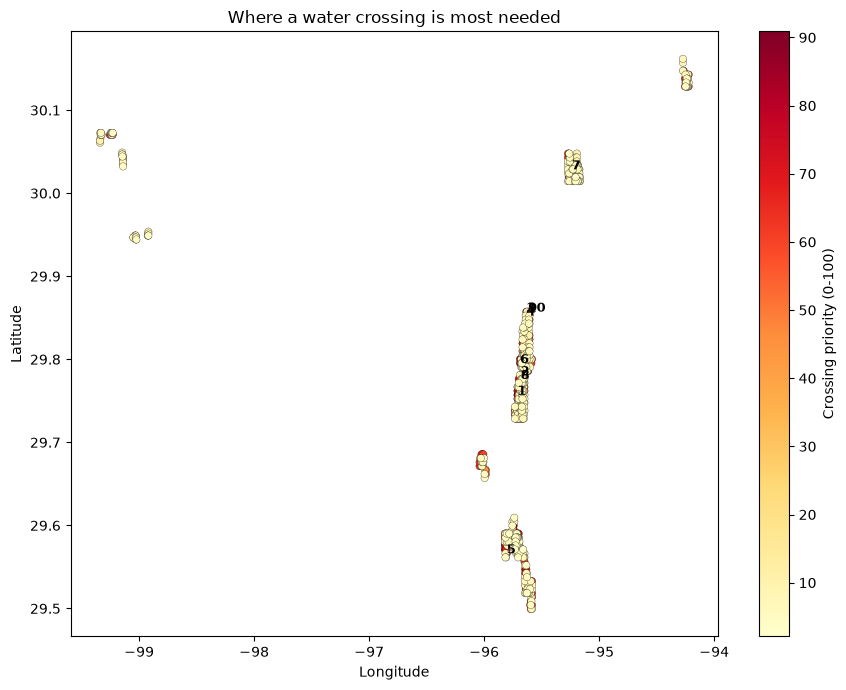

In [5]:
plot_map(ranked)

## Look at the top candidates
Check each against the images. Reject any the image does not support.

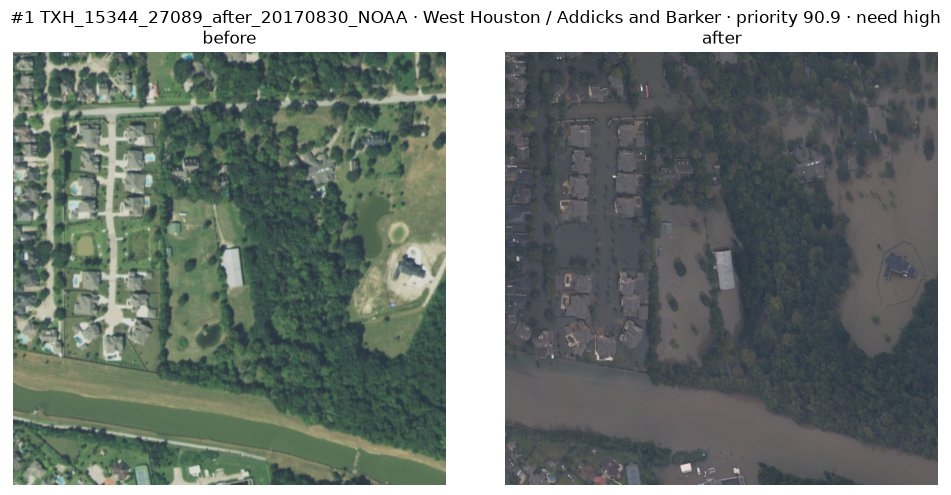

  - center, the road running through the flooded residential area: road is completely submerged, cutting off access to houses on both sides
  - right, the house surrounded by floodwater: house is isolated from road network by floodwater
  Uncertainty: flood extent and road visibility are partially obscured by water and vegetation. 



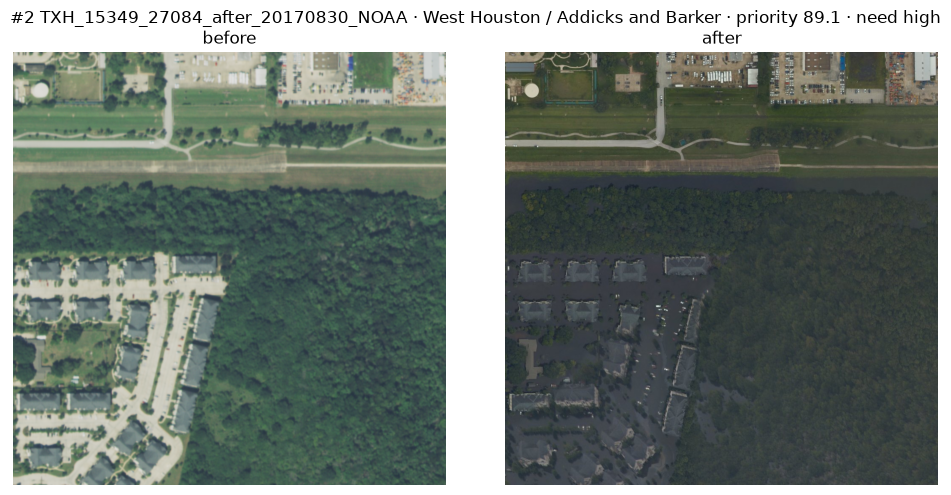

  - center, the road through the residential area: road is submerged and cut off from the upper road network
  - center, the residential area: houses are isolated by floodwater from the road network
  Uncertainty: Cannot confirm if water is deep enough to isolate all buildings or if any crossing exists. 



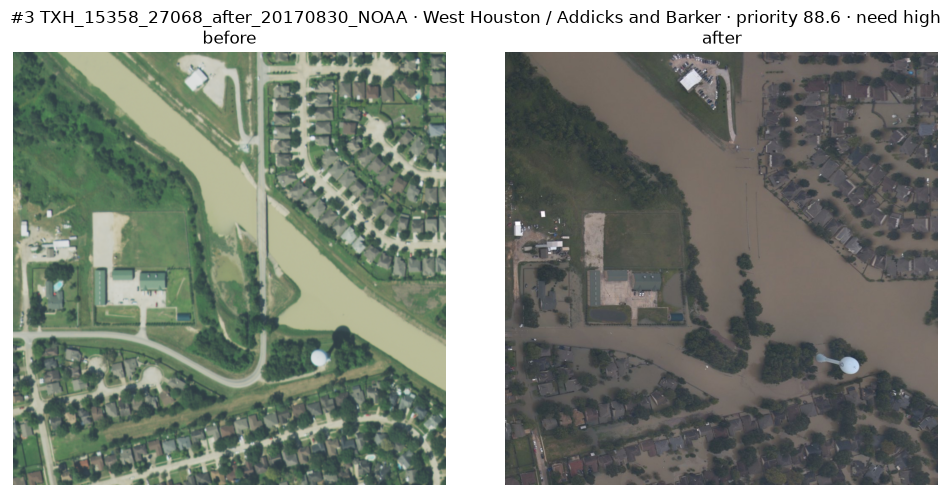

  - center, the main road crossing the river: road is completely submerged, cutting off access to both sides
  - bottom center, road near the water tower: road is flooded and surrounded by water, isolating buildings
  - top center, road near the industrial complex: road is submerged and surrounded by water, isolating buildings
  Uncertainty: The exact number of isolated buildings is estimated based on visible water coverage, but some may be obscured by trees or debris. 



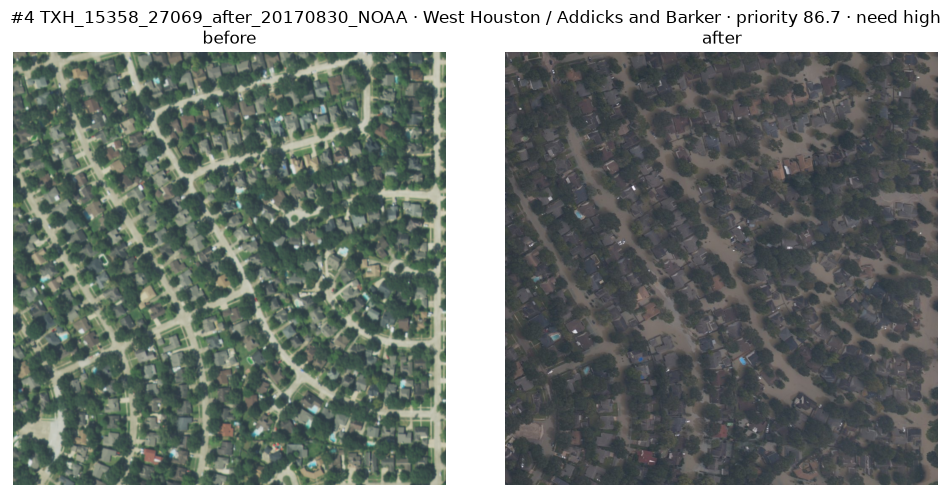

  - center, main diagonal road: road submerged with water covering entire width
  - center-left, perpendicular road: road submerged, water flowing through
  - top-center, road branching off main diagonal: road submerged, water covering surface
  - bottom-center, road with houses on both sides: road submerged, water isolating houses
  Uncertainty: Cannot confirm if water is flowing under roads or if structures are submerged beyond visible evidence. 



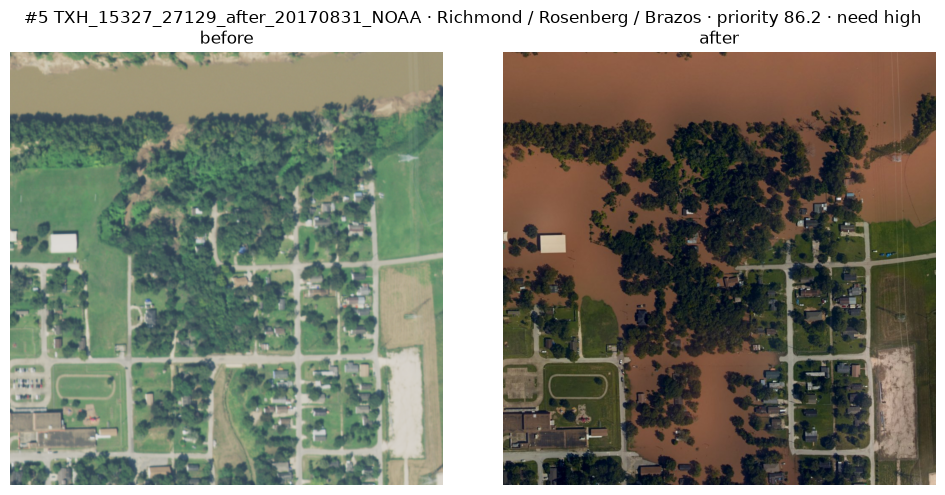

  - center, the main road crossing the flooded area: road is completely submerged, cutting off access to the right side of the image
  - center-left, road branching off the main road: road is submerged and surrounded by floodwater, isolating buildings on its left
  - bottom-center, road running horizontally: road is submerged and surrounded by floodwater, isolating buildings on its left and right
  Uncertainty: The exact number of isolated buildings and flooded roads is estimated based on visible water coverage; some submerged areas may be obscured by trees or vegetation. 



In [6]:
show_candidates(ranked, n=5)

## Save the ranking

In [7]:
import os
os.makedirs('results', exist_ok=True)
ranked.drop(columns=['raw','before_path','after_path']).to_csv('results/crossing_priority.csv', index=False)
neighborhoods(ranked).to_csv('results/neighborhood_priority.csv')
print('saved results/crossing_priority.csv and results/neighborhood_priority.csv')

saved results/crossing_priority.csv and results/neighborhood_priority.csv


## Check the model before trusting it
`export_review_sheet` writes a mixed sample (top, middle, bottom) to `results/review_sheet.csv`. Open the images, fill in the `human_need` column (`none`, `low`, `medium`, `high`), save, then run `agreement()`.

In [8]:
export_review_sheet(ranked).head()

,image_id,locality,crossing_need,priority,after_path,human_need
0,TXH_15344_27089_after_20170830_NOAA,West Houston / Addicks and Barker,high,90.9,C:\Users\Vince\Downloads\GB10competition\GB10c...,
1,TXH_15349_27084_after_20170830_NOAA,West Houston / Addicks and Barker,high,89.1,C:\Users\Vince\Downloads\GB10competition\GB10c...,
2,TXH_15358_27068_after_20170830_NOAA,West Houston / Addicks and Barker,high,88.6,C:\Users\Vince\Downloads\GB10competition\GB10c...,
3,TXH_15358_27069_after_20170830_NOAA,West Houston / Addicks and Barker,high,86.7,C:\Users\Vince\Downloads\GB10competition\GB10c...,
4,TXH_15327_27129_after_20170831_NOAA,Richmond / Rosenberg / Brazos,high,86.2,C:\Users\Vince\Downloads\GB10competition\GB10c...,


In [9]:
agreement()   # run after filling in human_need

Fill in the human_need column first.


## Limits
- The data covers Houston-area Hurricane Harvey (plus 54 Hill Country 2025 images). It says where water cut things off, not how much rain floods an area.
- County vulnerability figures are the same for every tile in a county.
- Nothing here proves a crossing would help; compare the top areas with San Antonio's low-water-crossing and storm-channel layers before acting.